# Reservas de hotel 
Makar Isaev m.isaev@alumnos.upm.es

In [0]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 52

d = pd.read_csv("01_reservas_hotel.csv")
print(d.head())

  id_reserva  antelacion_dias  noches  huespedes  precio_noche_eur  \
0     R00000                9       5          2            133.57   
1     R00001                8       4          3             61.00   
2     R00002               20       2          2             74.78   
3     R00003               23       4          3            106.67   
4     R00004               27       2          1            131.65   

   reservas_previas  ausencias_previas  cambios_reserva  \
0                 2                  0                1   
1                 0                  0                0   
2                 3                  0                1   
3                 2                  0                3   
4                 3                  0                0   

   solicitudes_especiales  deposito_pagado  llegada_fin_semana  no_presentado  
0                       0                1                   1              0  
1                       0                0                   1  

In [0]:
X = d.drop(columns=["id_reserva", "no_presentado"])
y = d["no_presentado"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Proporcion de no presentado:", round(y_train.mean(), 4))

Train: (4500, 10) Test: (1500, 10)
Proporcion de no presentado: 0.08


## 1. Seleccion de variables: FFS
Aplico Recursive Feature Elimination (RFE)

In [0]:
selector = RFE(
    estimator=LogisticRegression(class_weight="balanced", random_state=SEED),
    n_features_to_select=6,
)

pipe_all = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", random_state=SEED)),
    ]
)

pipe_rfe = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("rfe", selector),
        ("clf", LogisticRegression(class_weight="balanced", random_state=SEED)),
    ]
).set_output(transform="pandas")

pipe_rfe.fit(X_train, y_train)

tabla_ffs = pd.DataFrame(
    {
        "feature": selector.feature_names_in_,
        "ranking_rfe": selector.ranking_,
        "seleccionada": selector.support_,
    }
).sort_values("ranking_rfe")
print(tabla_ffs)

vars_sel = list(X.columns[selector.support_])
print("\nVariables seleccionadas:", vars_sel)

                  feature  ranking_rfe  seleccionada
0         antelacion_dias            1          True
6         cambios_reserva            1          True
5       ausencias_previas            1          True
4        reservas_previas            1          True
7  solicitudes_especiales            1          True
8         deposito_pagado            1          True
1                  noches            2         False
3        precio_noche_eur            3         False
9      llegada_fin_semana            4         False
2               huespedes            5         False

Variables seleccionadas: ['antelacion_dias', 'reservas_previas', 'ausencias_previas', 'cambios_reserva', 'solicitudes_especiales', 'deposito_pagado']


In [0]:
for name, p in [
    ("10 variables (todas)", pipe_all),
    ("6 variables (RFE)", pipe_rfe),
]:
    cv = cross_validate(p, X_train, y_train, cv=skf, scoring=["f1", "roc_auc"])
    print(
        f"{name}\nF1 CV: {cv['test_f1'].mean():.4f}\nROC-AUC CV: {cv['test_roc_auc'].mean():.4f}\n"
    )

10 variables (todas)
F1 CV: 0.2612
ROC-AUC CV: 0.7638

6 variables (RFE)
F1 CV: 0.2677
ROC-AUC CV: 0.7689



RFE descarta `noches`, `precio_noche_eur`, `llegada_fin_semana` y `huespedes`. Quedarnos con las 6 variables seleccionadas mantiene el mismo rendimiento con un modelo mas sencillo.

## 2. Un modelo interpretable
Uso Regresion Logistica. Como las variables estan estandarizadas, los coeficientes indican directamente el peso y el signo de cada variable en el resultado

In [0]:
y_pred_lr = pipe_rfe.predict(X_test)
y_prob_lr = pipe_rfe.predict_proba(X_test)[:, 1]

print("F1 en test:", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC test:", round(roc_auc_score(y_test, y_prob_lr), 4))
print(classification_report(y_test, y_pred_lr))

F1 en test: 0.2061
ROC-AUC test: 0.6867
              precision    recall  f1-score   support

           0       0.94      0.68      0.79      1380
           1       0.13      0.53      0.21       120

    accuracy                           0.67      1500
   macro avg       0.54      0.61      0.50      1500
weighted avg       0.88      0.67      0.75      1500



Intercepto: -0.4939

Coeficientes:
reservas_previas         -0.7708
deposito_pagado          -0.3376
solicitudes_especiales   -0.2525
antelacion_dias           0.1990
ausencias_previas         0.2472
cambios_reserva           0.3354
dtype: float64


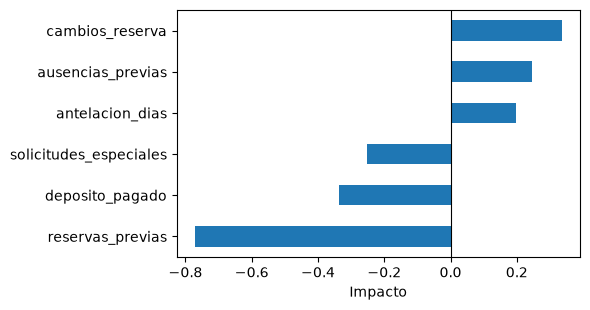

In [0]:
clf_lr = pipe_rfe.named_steps["clf"]
coefs = pd.Series(clf_lr.coef_[0], index=vars_sel).sort_values()
print("Intercepto:", round(clf_lr.intercept_[0], 4))
print("\nCoeficientes:")
print(coefs.round(4))

plt.figure(figsize=(6, 3.2))
coefs.plot(kind="barh")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Impacto")
plt.tight_layout()
plt.show()

- Aumentan el riesgo de no presentarse (coeficiente > 0): `cambios_reserva`, `ausencias_previas` y `antelacion_dias`.
- Reducen el riesgo de no presentarse (coeficiente < 0): `reservas_previas`, `deposito_pagado` y `solicitudes_especiales`.

## 3. Un modelo no interpretable y SHAP
Entreno un Random Forest. Uso RFE para acotar el estudio y verlo de manera mas clara

In [0]:
pipe_rf = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("rfe", selector),
        (
            "clf",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=5,
                class_weight="balanced",
                random_state=SEED,
            ),
        ),
    ]
).set_output(transform="pandas")

pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)
y_prob_rf = pipe_rf.predict_proba(X_test)[:, 1]

print("F1 test:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC test:", round(roc_auc_score(y_test, y_prob_rf), 4))
print(classification_report(y_test, y_pred_rf))

F1 test: 0.2292
ROC-AUC test: 0.7081
              precision    recall  f1-score   support

           0       0.95      0.68      0.79      1380
           1       0.14      0.61      0.23       120

    accuracy                           0.67      1500
   macro avg       0.55      0.64      0.51      1500
weighted avg       0.89      0.67      0.75      1500



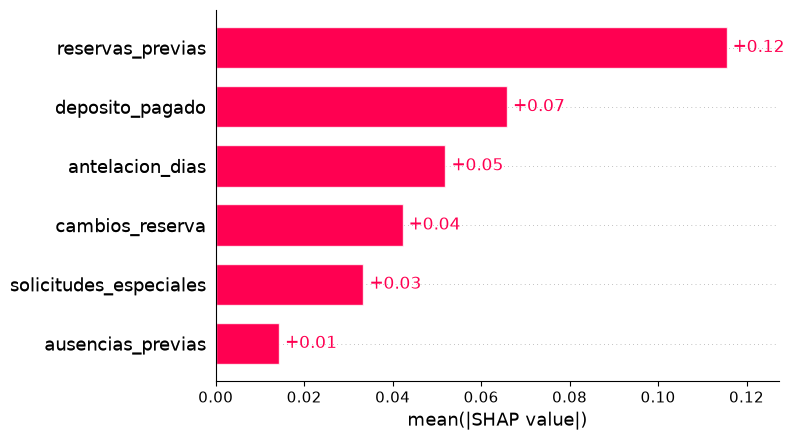

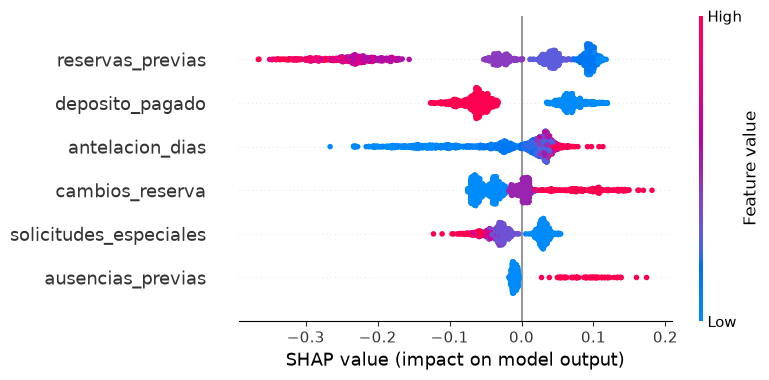

In [0]:
X_test_rf = pipe_rf[:-1].transform(X_test)
explainer = shap.TreeExplainer(pipe_rf.named_steps["clf"])
shap_values = explainer(X_test_rf)[:, :, 1]

plt.figure()
shap.plots.bar(shap_values, show=False)
plt.tight_layout()
plt.show()

plt.figure()
shap.plots.beeswarm(shap_values, show=False)
plt.tight_layout()
plt.show()

- Las variables mas importantes son `reservas_previas`, `deposito_pagado` y `antelacion_dias`, seguidas de `cambios_reserva`, `solicitudes_especiales` y `ausencias_previas`.
- En el segundo grafico, valores altos de `cambios_reserva`, `antelacion_dias` y `ausencias_previas` tienen valores SHAP positivos (empujan la prediccion hacia `no_presentado = 1`). Valores altos de `reservas_previas`, `deposito_pagado` y `solicitudes_especiales` tienen valores SHAP negativos (reducen el riesgo de ausencia).

### Explicacion local con SHAP

Reserva 8: real = 1, prob RF = 0.611
Reserva 0: real = 0, prob RF = 0.172


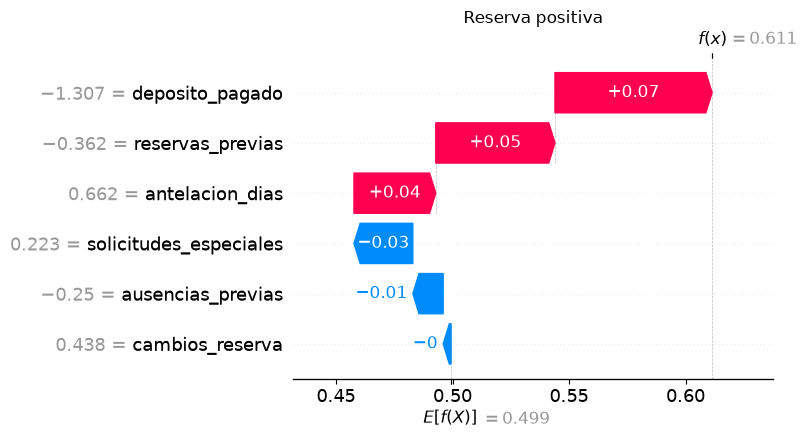

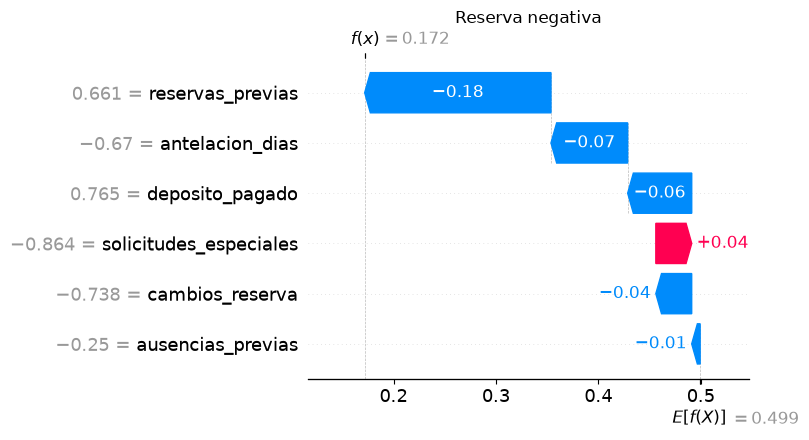

In [0]:
idx_pos = np.where(y_test == 1)[0][0]
idx_neg = np.where(y_test == 0)[0][0]

print(
    f"Reserva {idx_pos}: real = {y_test.iloc[idx_pos]}, prob RF = {y_prob_rf[idx_pos]:.3f}"
)
plt.figure()
shap.plots.waterfall(shap_values[idx_pos], show=False)
plt.title("Reserva positiva")
plt.tight_layout()
plt.show()

print(
    f"Reserva {idx_neg}: real = {y_test.iloc[idx_neg]}, prob RF = {y_prob_rf[idx_neg]:.3f}"
)
plt.figure()
shap.plots.waterfall(shap_values[idx_neg], show=False)
plt.title("Reserva negativa")
plt.tight_layout()
plt.show()

- Reserva positiva: parte del valor base ~0.50 y sube hasta 0.611 porque el cliente no ha pagado deposito (+0.07), tiene pocas reservas previas (+0.05) y reservo con 42 dias de antelacion (+0.04), mientras que tener una solicitud especial (-0.03) y no tener ausencias previas (-0.01) reducen un poco el riesgo.
- Reserva negativa: parte del valor base ~0.50 y baja hasta 0.172 porque el cliente tiene 4 reservas previas (-0.18), reservo con solo 8 dias de antelacion (-0.07), pago el deposito (-0.06) y no hizo cambios en la reserva (-0.04), aunque no tener solicitudes especiales suma un poco (+0.04).